## Library

In [ ]:
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

DOSSIER = Path("../dataset_computervision_LECSIN/dataset_squat")
GROUPES = ["pre", "per", "post"]
SEED = 42 
Path("figures").mkdir(exist_ok=True)

## Split Train / Val / Test data

In [15]:
# Inventaire des images (toutes personnes confondues)
fichiers = pd.DataFrame([
    {"chemin": str(chemin), "groupe": groupe}
    for groupe in GROUPES
    for chemin in sorted((DOSSIER / f"squat_{groupe}").glob("*.jpg"))
])

# Split aléatoire stratifié par groupe (60 / 20 / 20)
trainval, test = train_test_split(
    fichiers, test_size=0.20, stratify=fichiers["groupe"], random_state=SEED)
train, val = train_test_split(
    trainval, test_size=0.25, stratify=trainval["groupe"], random_state=SEED)

# Contrôle : aucune image dans deux jeux
assert not (set(train["chemin"]) & set(val["chemin"]))
assert not (set(train["chemin"]) & set(test["chemin"]))
assert not (set(val["chemin"]) & set(test["chemin"]))

splits = pd.concat([train.assign(jeu="train"), val.assign(jeu="val"), test.assign(jeu="test")])
splits.to_csv("splits.csv", index=False)

print(pd.crosstab(splits["jeu"], splits["groupe"]).loc[["train", "val", "test"], GROUPES])

groupe  pre  per  post
jeu                   
train   300  300   300
val     100  100   100
test    100  100   100


## Face detection function

In [16]:
# Viola-Jones face detection algorithm (cascade chargée une seule fois)
_CASCADE = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
if _CASCADE.empty():
    raise RuntimeError("Cascade non chargée : vérifie l'installation d'OpenCV (<5)")


def detecter_visage(image, scale_factor=1.1, min_neighbors=5,
                    min_size=(60, 60), roi_ratio=1.0):
    """
    Détecte le visage (Viola-Jones) et retourne le recadrage BGR.
    image     : chemin (str / Path) ou tableau BGR
    roi_ratio : fraction centrale de la boîte conservée (0.6 = centre du visage)
    Retourne (visage_bgr, bbox) ou (None, None) si aucun visage.
    """
    img = cv2.imread(str(image)) if isinstance(image, (str, Path)) else image
    if img is None:
        raise FileNotFoundError(f"Image illisible : {image}")

    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    visages = _CASCADE.detectMultiScale(
        gris, scaleFactor=scale_factor,
        minNeighbors=min_neighbors, minSize=min_size,
    )
    if len(visages) == 0:
        return None, None

    x, y, w, h = max(visages, key=lambda b: b[2] * b[3])   # on garde le plus grand
    dx, dy = int(w * (1 - roi_ratio) / 2), int(h * (1 - roi_ratio) / 2)
    visage = img[y + dy : y + h - dy, x + dx : x + w - dx]
    return visage, (int(x), int(y), int(w), int(h))

## Fondamentales features


In [ ]:
CANAUX = ("B", "G", "R")   # ordre OpenCV


def _valeur_max(img):
    """Input : image BGR (uint8, uint16, float32, float64). 
    Output: valeur max possible.
    Objectif : normaliser les valeurs dans [0, 1] pour calculer la luminance."""
    return float(np.iinfo(img.dtype).max) if np.issubdtype(img.dtype, np.integer) else 1.0


def srgb_vers_lineaire(img_bgr):
    """Input : 
    image BGR (uint8, uint16, float32, float64).
    Output: image linéaire dans [0, 1].
    Objectif : convertir sRGB (non linéaire) -> lumière linéaire, valeurs dans [0, 1]."""
    c = img_bgr.astype(np.float64) / _valeur_max(img_bgr)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _luminance(bgr_norm):
    """Input: image BGR dans [0, 1].
    Output: luminance Rec.709.
    Objectif: calculer la luminance Rec.709 depuis une image BGR dans [0, 1]."""
    return 0.0722 * bgr_norm[..., 0] + 0.7152 * bgr_norm[..., 1] + 0.2126 * bgr_norm[..., 2]


def feature_profondeur_bits(img):
    """Input : image BGR (uint8, uint16, float32, float64).
    Output: dictionnaire de features sur la profondeur de bits et l'utilisation des niveaux.
    Objectif : caractériser la profondeur de bits et l'utilisation des niveaux par canal."""
    bits = img.dtype.itemsize * 8
    feats = {"bits_par_canal": bits}
    for i, nom in enumerate(CANAUX):
        n_uniques = len(np.unique(img[..., i]))
        feats[f"valeurs_uniques_{nom}"] = n_uniques
        feats[f"utilisation_niveaux_{nom}_pct"] = 100 * n_uniques / 2 ** bits
    return feats


def feature_gamma(img):
    """Input : image BGR (uint8, uint16, float32, float64).
    Output: dictionnaire de features sur la luminance et les canaux.
    Objectif : calculer les features de gamma pour chaque canal."""
    srgb = img.astype(np.float64) / _valeur_max(img)
    lin = srgb_vers_lineaire(img)
    feats = {}
    for i, nom in enumerate(CANAUX):
        feats[f"moyenne_srgb_{nom}"] = float(srgb[..., i].mean())
        feats[f"moyenne_lin_{nom}"] = float(lin[..., i].mean())
    feats["luma_srgb_moy"] = float(_luminance(srgb).mean())
    feats["luminance_lin_moy"] = float(_luminance(lin).mean())
    return feats


def feature_plage_dynamique(img, eps=1e-4):
    """Input : image BGR (uint8, uint16, float32, float64).
    Output: dictionnaire de features sur la plage dynamique et le contraste.
    Objectif : calculer les features de plage dynamique et de contraste."""
    srgb = img.astype(np.float64) / _valeur_max(img)
    luma = _luminance(srgb).ravel()
    lum_lin = _luminance(srgb_vers_lineaire(img)).ravel()
    p1, p99 = np.percentile(lum_lin, [1, 99])
    l1, l99 = np.percentile(luma, [1, 99])
    return {
        "luma_min": float(luma.min()),
        "luma_max": float(luma.max()),
        "luma_p1": float(l1),
        "luma_p99": float(l99),
        "etendue_p1_p99": float(l99 - l1),
        "plage_dynamique_stops": float(np.log2((p99 + eps) / (p1 + eps))),
        "contraste_rms": float(luma.std()),
        "contraste_michelson": float((l99 - l1) / (l99 + l1 + 1e-9)),
        "pct_sature": float(100 * np.mean(luma >= 0.98)),
        "pct_sous_expose": float(100 * np.mean(luma <= 0.02)),
    }

## Colorimetry function

In [ ]:
def colorimetry(chemin, roi_ratio=0.6):
    """Input : chemin de l'image à analyser, ratio de la région d'intérêt.
    Output: dictionnaire de features colorimétriques.
    Objectif : extraire les features colorimétriques d'une image.
    Assemble tous les blocs de features sur le visage. Retourne None si pas de visage.
    Les prochains blocs (HSV, YCbCr, Lab, ITA...) s'ajouteront ici."""
    visage, bbox = detecter_visage(chemin, roi_ratio=roi_ratio)
    if visage is None:
        return None
    feats = {}
    feats.update(feature_profondeur_bits(visage))
    feats.update(feature_gamma(visage))
    feats.update(feature_plage_dynamique(visage))
    return feats


# Extraction sur tout le dataset (le split est déjà fait, on garde la colonne "jeu")
lignes, sans_visage = [], 0
for ligne in splits.itertuples(index=False):
    feats = colorimetry(ligne.chemin)
    if feats is None:
        sans_visage += 1
        continue
    lignes.append({"chemin": ligne.chemin, "groupe": ligne.groupe,
                   "jeu": ligne.jeu, **feats})

data = pd.DataFrame(lignes)
data.to_csv("features_colorimetry.csv", index=False)

print(f"{len(data)} images exploitables, {sans_visage} sans visage détecté")
print(pd.crosstab(data["jeu"], data["groupe"]).loc[["train", "val", "test"], GROUPES])

1478 images exploitables, 22 sans visage détecté
groupe  pre  per  post
jeu                   
train   295  295   294
val     100   99    99
test     98   99    99


## Training

In [20]:
META = ["chemin", "groupe", "jeu"]
EXCLURE = ("bits_par_canal", "valeurs_uniques", "utilisation_niveaux")  # contrôle qualité
FEATURES = [c for c in data.columns if c not in META and not c.startswith(EXCLURE)]

d_train, d_val, d_test = (data[data["jeu"] == j] for j in ("train", "val", "test"))
X_train, y_train = d_train[FEATURES], d_train["groupe"]
X_val,   y_val   = d_val[FEATURES],   d_val["groupe"]
X_test,  y_test  = d_test[FEATURES],  d_test["groupe"]
print(f"{len(FEATURES)} features utilisées")

modeles = {
    "Baseline (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
}

# Comparaison sur la validation
scores = {}
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    pred = modele.predict(X_val)
    scores[nom] = {"accuracy": accuracy_score(y_val, pred),
                   "balanced_accuracy": balanced_accuracy_score(y_val, pred)}

scores_df = pd.DataFrame(scores).T.round(3)
print(scores_df)

meilleur = max(scores, key=lambda n: scores[n]["balanced_accuracy"])
print("Meilleur modèle sur validation :", meilleur)

# Modèle final : réentraîné sur train + val
modele_final = modeles[meilleur]
modele_final.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

18 features utilisées
                               accuracy  balanced_accuracy
Baseline (classe majoritaire)     0.332              0.333
Régression logistique             0.859              0.859
Random Forest                     0.966              0.967
Meilleur modèle sur validation : Random Forest


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

## Results

Modèle : Random Forest
Accuracy          : 0.963
Balanced accuracy : 0.963

              precision    recall  f1-score   support

         pre       0.98      0.98      0.98        98
         per       0.94      0.99      0.97        99
        post       0.97      0.92      0.94        99

    accuracy                           0.96       296
   macro avg       0.96      0.96      0.96       296
weighted avg       0.96      0.96      0.96       296



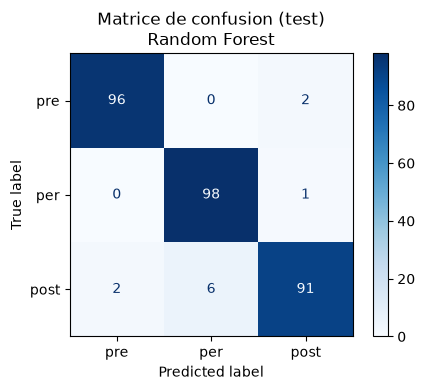

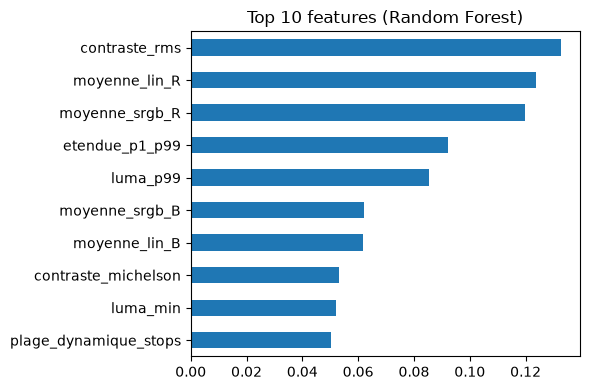

In [21]:
# Évaluation finale sur le test (une seule fois)
pred_test = modele_final.predict(X_test)

print(f"Modèle : {meilleur}")
print(f"Accuracy          : {accuracy_score(y_test, pred_test):.3f}")
print(f"Balanced accuracy : {balanced_accuracy_score(y_test, pred_test):.3f}\n")
print(classification_report(y_test, pred_test, labels=GROUPES, zero_division=0))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, labels=GROUPES, cmap="Blues", ax=ax)
ax.set_title(f"Matrice de confusion (test)\n{meilleur}")
plt.tight_layout()
plt.savefig("figures/confusion_colorimetry_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

# Importance des features (Random Forest entraîné sur train)
rf = modeles["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(10)
imp.plot.barh(figsize=(6, 4), title="Top 10 features (Random Forest)")
plt.tight_layout()
plt.savefig("figures/importance_features_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

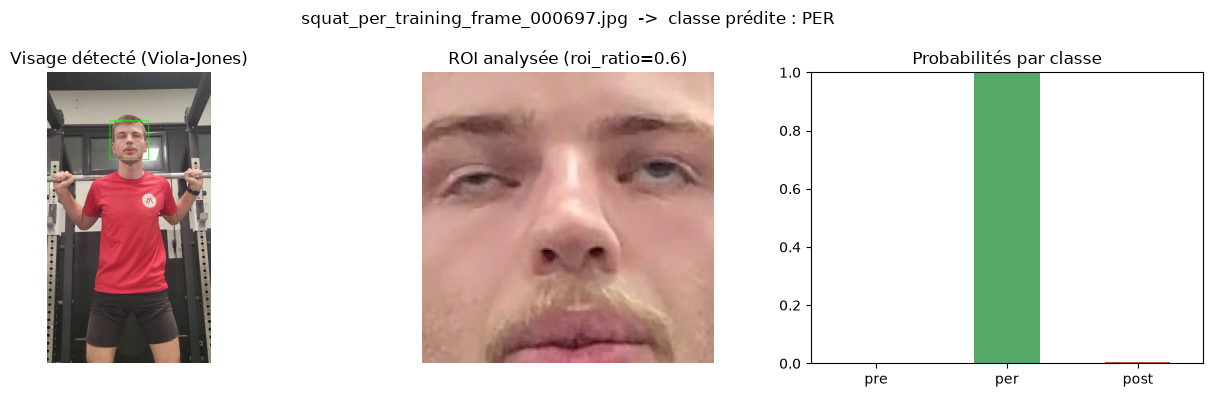

Classe prédite : per
per     0.997
post    0.003
pre     0.000

Features utilisées par le modèle :
  - moyenne_srgb_B
  - moyenne_lin_B
  - moyenne_srgb_G
  - moyenne_lin_G
  - moyenne_srgb_R
  - moyenne_lin_R
  - luma_srgb_moy
  - luminance_lin_moy
  - luma_min
  - luma_max
  - luma_p1
  - luma_p99
  - etendue_p1_p99
  - plage_dynamique_stops
  - contraste_rms
  - contraste_michelson
  - pct_sature
  - pct_sous_expose


In [28]:
def tester_image(chemin, roi_ratio=0.6):
    """Teste le modèle sur une image : visage détecté, features, classe prédite."""
    chemin = Path(chemin)

    # 1) Détection du visage (boîte complète pour l'affichage, ROI pour l'analyse)
    img = cv2.imread(str(chemin))
    if img is None:
        raise FileNotFoundError(f"Image illisible : {chemin}")
    visage, bbox = detecter_visage(img, roi_ratio=roi_ratio)
    if visage is None:
        print("Aucun visage détecté : impossible de classer cette image.")
        return None

    # 2) Features -> DataFrame avec les colonnes et l'ordre de l'entraînement
    feats = colorimetry(chemin, roi_ratio=roi_ratio)
    X = pd.DataFrame([feats])[FEATURES]

    # 3) Prédiction
    pred = modele_final.predict(X)[0]
    proba = None
    if hasattr(modele_final, "predict_proba"):
        proba = pd.Series(modele_final.predict_proba(X)[0], index=modele_final.classes_)

    # 4) Affichage : image annotée, ROI analysée, probabilités
    x, y, w, h = bbox
    annotee = img.copy()
    cv2.rectangle(annotee, (x, y), (x + w, y + h), (0, 255, 0), 3)

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(cv2.cvtColor(annotee, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Visage détecté (Viola-Jones)")
    axes[1].imshow(cv2.cvtColor(visage, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"ROI analysée (roi_ratio={roi_ratio})")
    if proba is not None:
        proba.reindex(GROUPES).plot.bar(ax=axes[2], color=["#4C72B0", "#55A868", "#C44E52"])
        axes[2].set_ylim(0, 1)
        axes[2].set_title("Probabilités par classe")
        axes[2].tick_params(axis="x", rotation=0)
    for ax in axes[:2]:
        ax.axis("off")
    plt.suptitle(f"{chemin.name}  ->  classe prédite : {pred.upper()}", fontsize=12)
    plt.tight_layout()
    plt.show()

    # 5) Features extraites (uniquement celles utilisées par le modèle)
    print(f"Classe prédite : {pred}")
    if proba is not None:
        print(proba.round(3).to_string())
    print("\nFeatures utilisées par le modèle :")
    for f in FEATURES:
        print(f"  - {f}")

#tester une image
tester_image("../dataset_computervision_LECSIN/dataset_squat/squat_per/squat_per_training_frame_000697.jpg")